In [7]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np

In [8]:
df = yf.download("EURUSD=X", start="2020-01-01", end="2024-12-31", interval="1d")
df.columns = df.columns.get_level_values(0)
df = df[["Close"]].dropna()
print(df.head())

[*********************100%***********************]  1 of 1 completed

Price          Close
Date                
2020-01-01  1.122083
2020-01-02  1.122083
2020-01-03  1.117144
2020-01-06  1.116196
2020-01-07  1.119799


In [9]:
df["SMA_short"] = df["Close"].rolling(10).mean()
df["SMA_long"] = df["Close"].rolling(50).mean()
df["SMA_signal"] = (df["SMA_short"] > df["SMA_long"]).astype(int)

delta = df["Close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = -delta.clip(upper=0).rolling(14).mean()
df["RSI"] = 100 - (100/(1+(gain/loss)))
df["RSI_signal"] = (df["RSI"] < 30).astype(int)

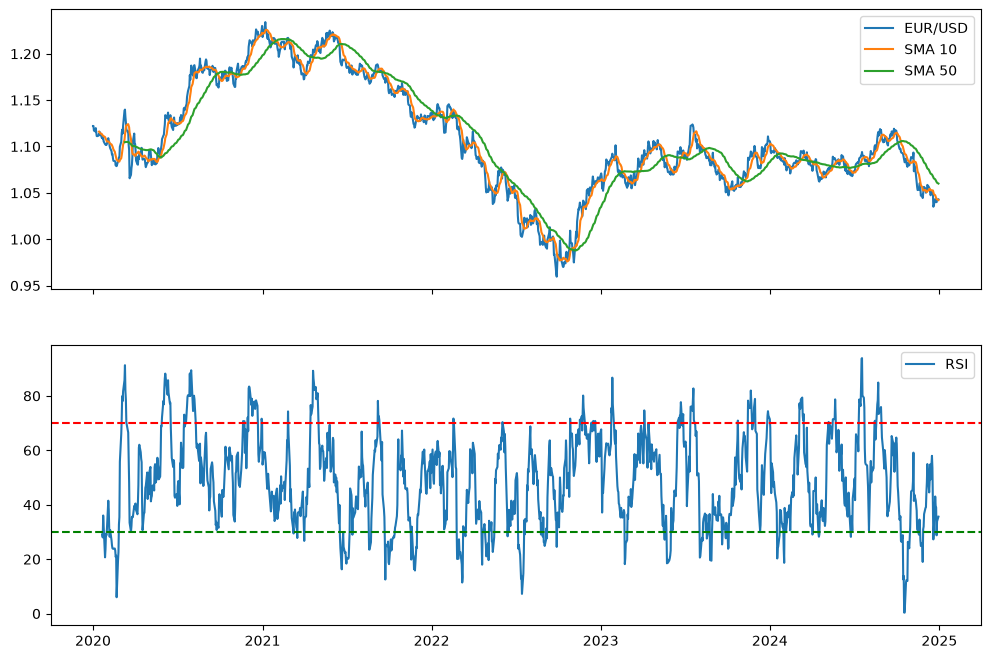

In [10]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.plot(df["Close"], label="EUR/USD")
ax1.plot(df["SMA_short"], label="SMA 10")
ax1.plot(df["SMA_long"], label="SMA 50")
ax1.legend()
ax2.plot(df["RSI"], label="RSI")
ax2.axhline(30, color="green", linestyle="--")
ax2.axhline(70, color="red", linestyle="--")
ax2.legend()
plt.show()

In [11]:
log_return = np.log(df["Close"]).diff()
log_return

Date
2020-01-01         NaN
2020-01-02    0.000000
2020-01-03   -0.004411
2020-01-06   -0.000849
2020-01-07    0.003223
                ...   
2024-12-24   -0.002615
2024-12-25   -0.000312
2024-12-26   -0.000291
2024-12-27    0.002270
2024-12-30    0.000594
Name: Close, Length: 1304, dtype: float64